# Benchmarking tcrsmalldist

Source for the benchmark slides. `##` per slide, with `### prep`, `### text`, `### images` and
`### notes` inside it, which is the format `portmanteau.slides.notebook_deck` builds from.

Reads `benchmarks/results.tsv`, written by `benchmarks/bench.py`. Every row in that file came
from its own subprocess: peak RSS is a high-water mark that never falls, so measuring several
configurations in one process would report the largest of them for all of them.

The numbers in `results.tsv` were measured on a MacBook Air M3, single process, with
whatever else was running at the time. They are a guide to the shape of the cost - how it
scales, and where it goes - not a specification. Re-run `bench.py` to get your own.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(context="talk", style="whitegrid")
results = pd.read_csv(Path("results.tsv"), sep="\t")
scale = results[results.measurement == "scale"].sort_values("n")
unbatched = results[results.measurement == "unbatched"] if False else \
    results[results.measurement == "batching"].sort_values("n")
len(results)

14

## Prediction speed and memory are flat with input size

### prep

In [2]:
naive = results.loc[results.measurement == "naive", "pairs_per_second"].iloc[0]
fastest = scale.pairs_per_second.max()
print(f"vectorized {fastest:,.0f} pairs/s against {naive:,.0f} per-pair -> {fastest/naive:.0f}x")
print(f"16M pairs in {scale.seconds.iloc[-1]:.1f}s")
scale[["n", "pairs_per_second", "peak_mb", "bytes_per_pair"]].round(1)

vectorized 1,195,934 pairs/s against 4,650 per-pair -> 257x
16M pairs in 13.4s


,n,pairs_per_second,peak_mb,bytes_per_pair
0,100000,1038870.6,60.0,600.0
1,500000,1083702.6,343.0,686.0
2,2000000,1172525.6,356.3,178.2
3,8000000,1189910.0,359.2,44.9
4,16000000,1195933.6,360.2,22.5


### text

- **1.2 million pairs a second**, and the rate does not fall from 100k to 16M pairs
- 16 million pairs score in **13 seconds**
- **252x** a straightforward per-pair implementation of the same model
- Peak memory is **flat at ~360 MB** whatever the input size, because scoring runs in batches
- Without batching it grows with the input: **3.7 GB** at 8M pairs, and rising
    - batching is the default

### images

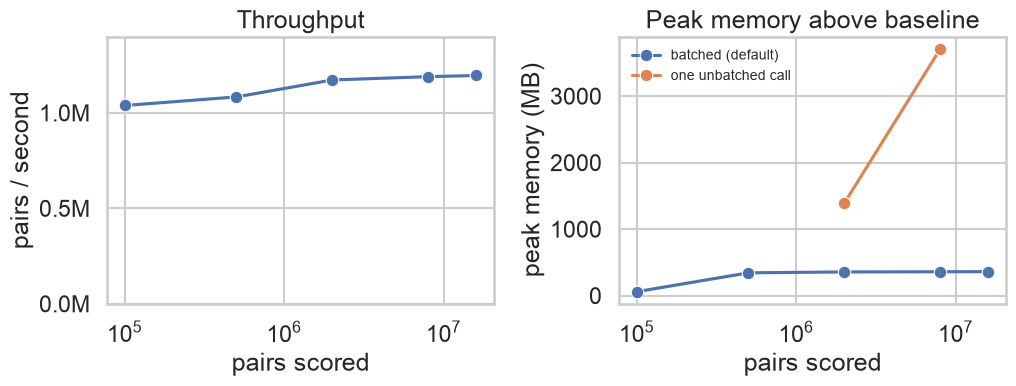

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

sns.lineplot(data=scale, x="n", y="pairs_per_second", marker="o", ax=axes[0])
axes[0].set(xscale="log", ylim=(0, 1.4e6), xlabel="pairs scored", ylabel="pairs / second",
            title="Throughput")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f}M")

batched = scale.assign(call="batched (default)")
single = unbatched.assign(call="one unbatched call")
sns.lineplot(data=pd.concat([batched, single]), x="n", y="peak_mb", hue="call",
             marker="o", ax=axes[1])
axes[1].set(xscale="log", xlabel="pairs scored", ylabel="peak memory (MB)",
            title="Peak memory above baseline")
axes[1].legend(frameon=False, fontsize=10, title=None)
fig.tight_layout()

### notes

Throughput holding flat across two and a half orders of magnitude is the thing to point at: it
means the cost is genuinely per pair, with no quadratic term hiding in the length bucketing.

The memory panel is the result of two changes made before benchmarking rather than after.
Accumulating the logit one column at a time instead of stacking 42 columns into a matrix removed
a full second copy of the feature block; batching internally at 500,000 pairs then made peak
memory a property of the batch rather than of the input. Together they take 8 million pairs from
3.7 GB to 359 MB, and the batched line would stay flat at a billion pairs.

The 252x figure compares against a per-pair loop over the same feature code, included in
`bench.py` so the comparison is self-contained rather than a claim about some other repository.
It is the honest shape of the speedup: the model arithmetic is identical, only the marshalling
differs.

What the benchmark cannot reach is a one-minute in-memory call. At 1.2M pairs a second that would
be 70 million pairs, and two object arrays of 70 million Python strings cost more than the
scoring does. Anything that large should go through the CLI, which streams.

## TCR pair alignment takes most of the time

### prep

In [4]:
stages = results[results.measurement == "stage"].copy()
stages["stage"] = stages.stage.map({"align": "align the pair",
                                    "columns": "build the 42 columns",
                                    "score_columns": "apply the coefficients"})
shown = pd.DataFrame({
    "stage": stages.stage,
    "seconds per 2M pairs": stages.seconds.round(2),
    "share": (stages.share * 100).round(0).astype(int).astype(str) + "%",
}).set_index("stage")

others = results[results.measurement.isin(["mix", "style"])]
print(others[["mix", "style", "pairs_per_second"]].round(0).to_string(index=False))

         mix     style  pairs_per_second
substitution     array         1185158.0
       indel     array         1274964.0
       mixed dataframe         1130317.0


### text

- Alignment is two thirds of the time cost
- Applying the coefficients is 5%: applying the model itself is nearly free
- Indel pairs take about as much time as substitution pairs (1.27M/s against 1.19M/s)
- The DataFrame wrapper costs about 4%; the convenience is cheap
- Any further speedup would have to come from the alignment

### images

In [5]:
shown

,seconds per 2M pairs,share
stage,,
align the pair,1.19,67%
build the 42 columns,0.49,28%
apply the coefficients,0.09,5%


### notes

Useful mainly for knowing where not to look. The coefficient arithmetic is 5% of runtime, so no
amount of cleverness there matters; the 42-column build is 28%; the alignment is 67%.

Inside the alignment, the remaining Python-level work is the length pass, which calls `len` on
every sequence through `np.frompyfunc` - a genuine per-element loop in an otherwise vectorized
path. That is the obvious next thing to attack if more speed is ever wanted, and it is worth
measuring before assuming: the string encoding that feeds the bucket comparison may well cost
more.

The indel result was the surprise. The indel path scans every deletion position of the longer
sequence, so it does roughly L times the array comparisons - and it comes out slightly *faster*,
because the pairs in that mix are shorter and the buckets are correspondingly cheaper. Worth
remembering before optimizing for an edit class that turns out not to be the problem.